Saving modified_hansen_data.csv to modified_hansen_data.csv
Dataset path: data/modified_hansen_data.csv
Original rows: 214558
Rows after cleaning: 214558
BAC range: 0.0 to 0.435
Overall recidivism rate: 0.1176
Prior-experience variable: None
male unique values: [0, 1]
white unique values: [0, 1]
acc unique values: [0, 1]
recidivism unique values: [0, 1]
dui unique values: [0, 1]
agg_dui unique values: [0, 1]
Single-characteristic specifications:
 - Age only ['aged']
 - Male only ['male']
 - White only ['white']
 - Accident at initial stop only ['acc']
 - Year only ['year']

Nested specifications:
 - Age ['aged']
 - Age + Male ['aged', 'male']
 - Age + Male + White ['aged', 'male', 'white']
 - Age + Male + White + Accident at initial stop ['aged', 'male', 'white', 'acc']
 - Age + Male + White + Accident at initial stop + Year ['aged', 'male', 'white', 'acc', 'year']

Predetermined-covariate balance checks at the 0.08 cutoff:
  characteristic  coefficient  standard_error  ci_lower  ci_up

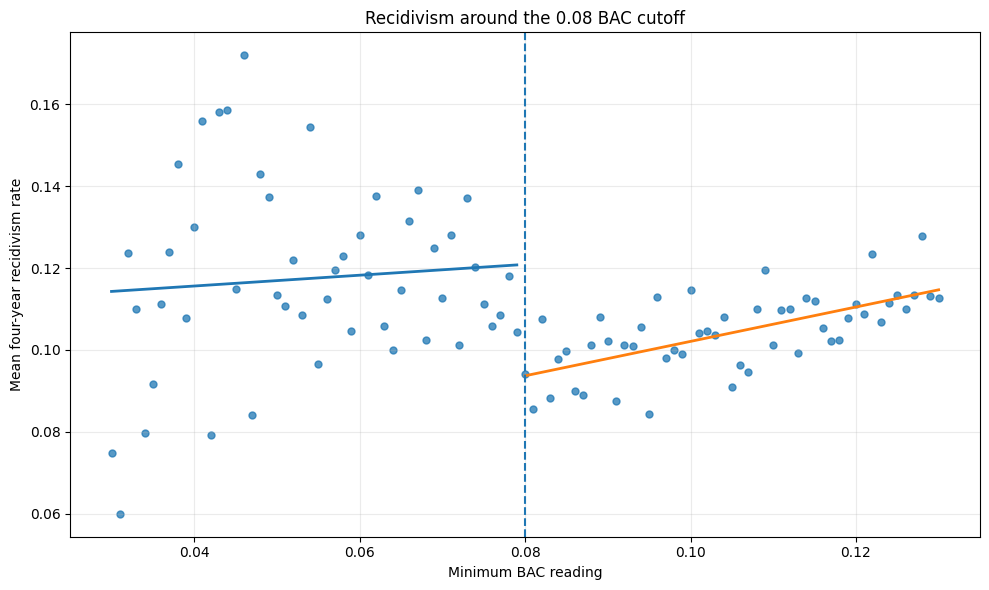


Hansen benchmark estimates used in the difference tests:
   bandwidth  hansen_estimate  hansen_standard_error  hansen_observations  \
0      0.050           -0.021                  0.004                95111   
1      0.025           -0.019                  0.005                49396   

                                              source  
0  Hansen (2015), Table 3, Panel A, all tested dr...  
1  Hansen (2015), Table 3, Panel B, all tested dr...  

Fitting primary forest: Age only

Fitting primary forest: Male only

Fitting primary forest: White only

Fitting primary forest: Accident at initial stop only

Fitting primary forest: Year only

Primary one-characteristic-at-a-time GRF results:
              model_type                  specification variables  bandwidth  \
0  Single characteristic                       Age only      aged       0.05   
1  Single characteristic                      Male only      male       0.05   
2  Single characteristic                     White only    

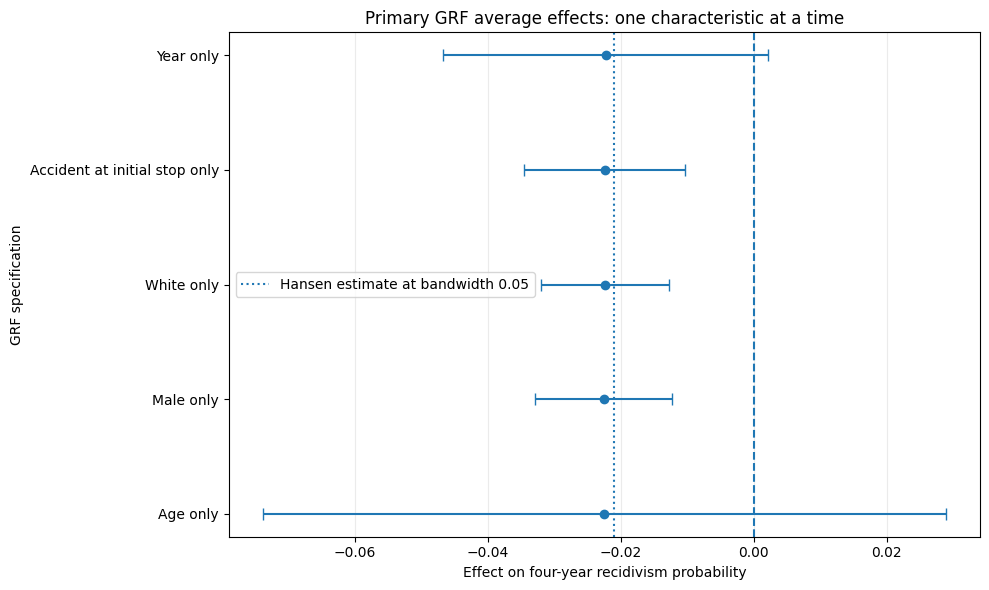


Interpretable treatment-effect profiles:
                    specification variable  group  plot_value  observations  \
0                        Age only     aged  20-24     22.3761         24206   
1                        Age only     aged  25-29     26.7879         18138   
2                        Age only     aged  30-34     31.9110         12599   
3                        Age only     aged  35-39     36.9708         10984   
4                        Age only     aged  40-44     41.9539          9796   
5                        Age only     aged  45-49     46.8381          7456   
6                        Age only     aged  50-54     51.8217          4940   
7                        Age only     aged  55-59     56.7842          2813   
8                        Age only     aged  60-64     61.7610          1460   
9                        Age only     aged  65-69     66.7022           759   
10                       Age only     aged  70-74     71.8020           404   
11        

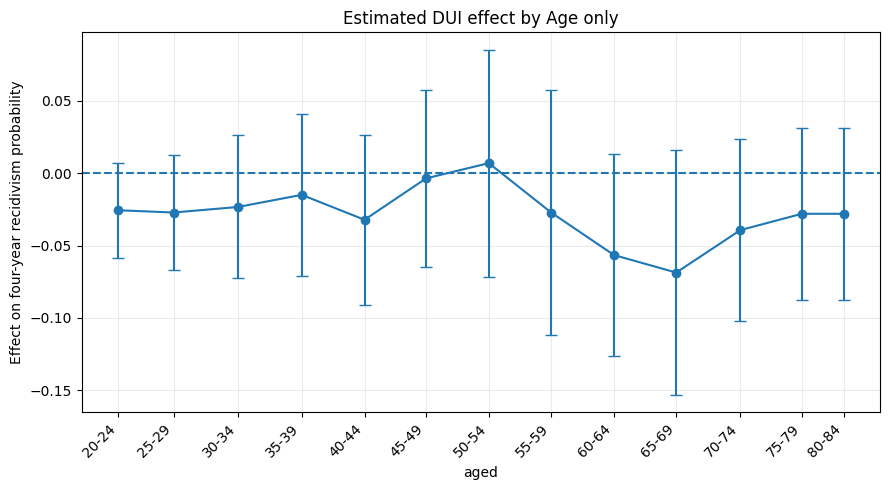

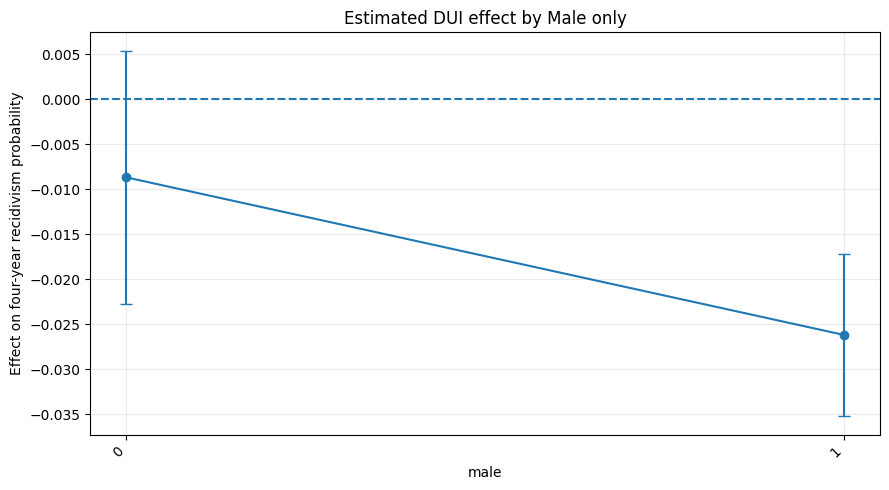

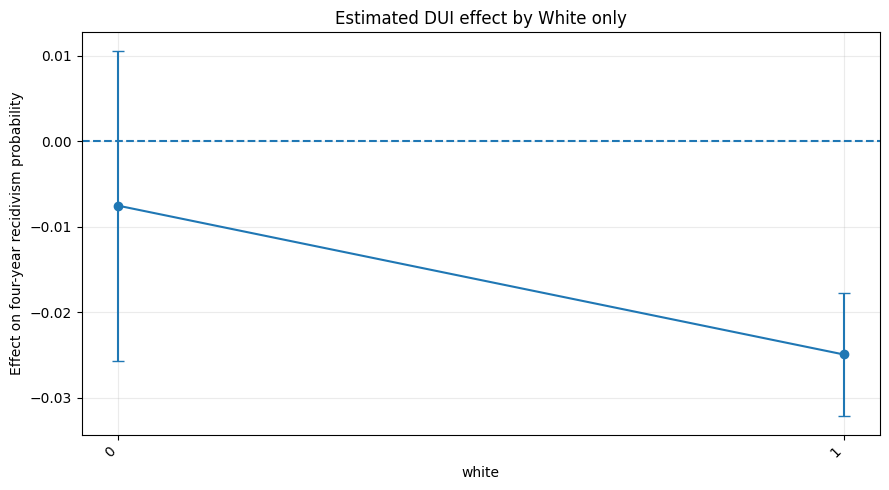

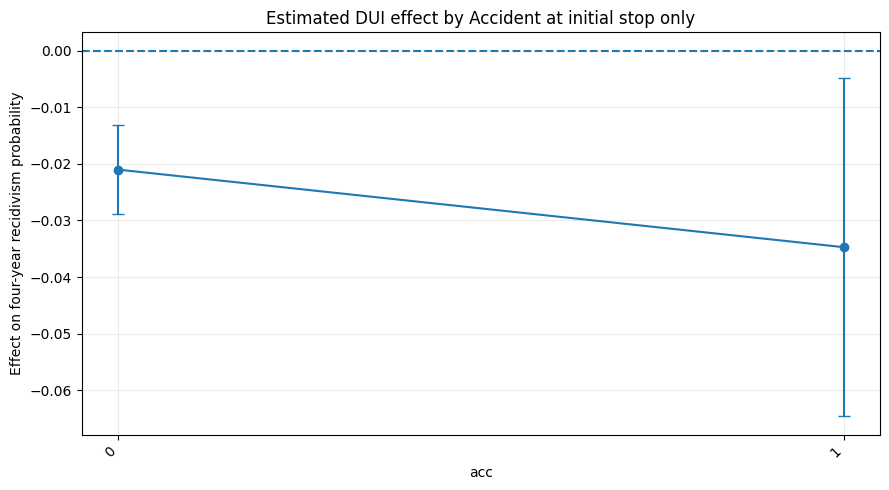

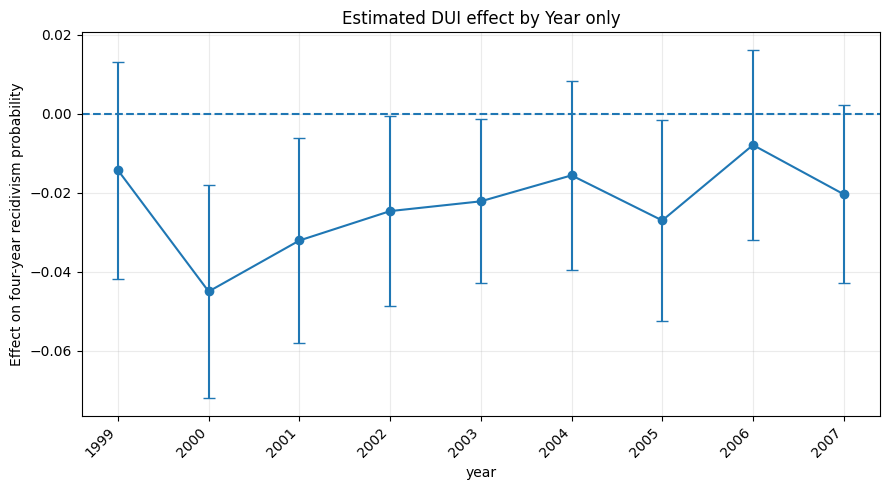


Bandwidth GRF: Age only, bandwidth=0.015

Bandwidth GRF: Age only, bandwidth=0.025

Bandwidth GRF: Age only, bandwidth=0.035

Bandwidth GRF: Age only, bandwidth=0.050

Bandwidth GRF: Age only, bandwidth=0.065

Bandwidth GRF: Male only, bandwidth=0.015

Bandwidth GRF: Male only, bandwidth=0.025

Bandwidth GRF: Male only, bandwidth=0.035

Bandwidth GRF: Male only, bandwidth=0.050

Bandwidth GRF: Male only, bandwidth=0.065

Bandwidth GRF: White only, bandwidth=0.015

Bandwidth GRF: White only, bandwidth=0.025

Bandwidth GRF: White only, bandwidth=0.035

Bandwidth GRF: White only, bandwidth=0.050

Bandwidth GRF: White only, bandwidth=0.065

Bandwidth GRF: Accident at initial stop only, bandwidth=0.015

Bandwidth GRF: Accident at initial stop only, bandwidth=0.025

Bandwidth GRF: Accident at initial stop only, bandwidth=0.035

Bandwidth GRF: Accident at initial stop only, bandwidth=0.050

Bandwidth GRF: Accident at initial stop only, bandwidth=0.065

Bandwidth GRF: Year only, bandwidth=0.0

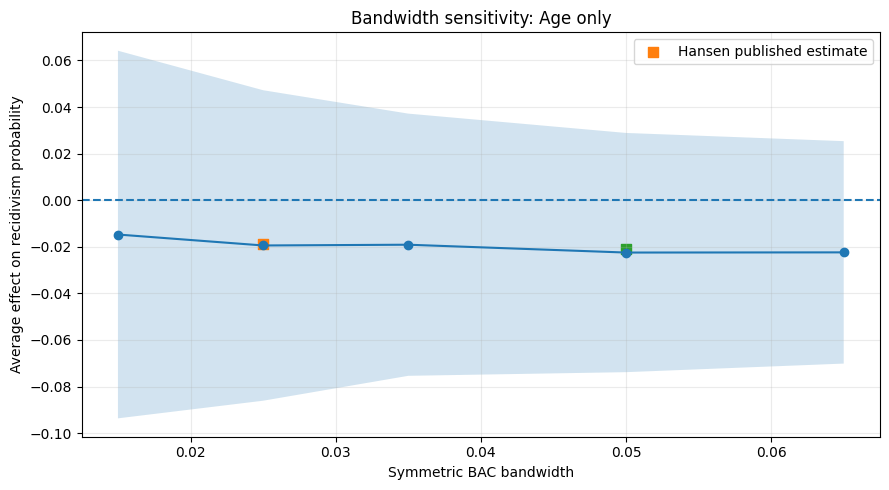

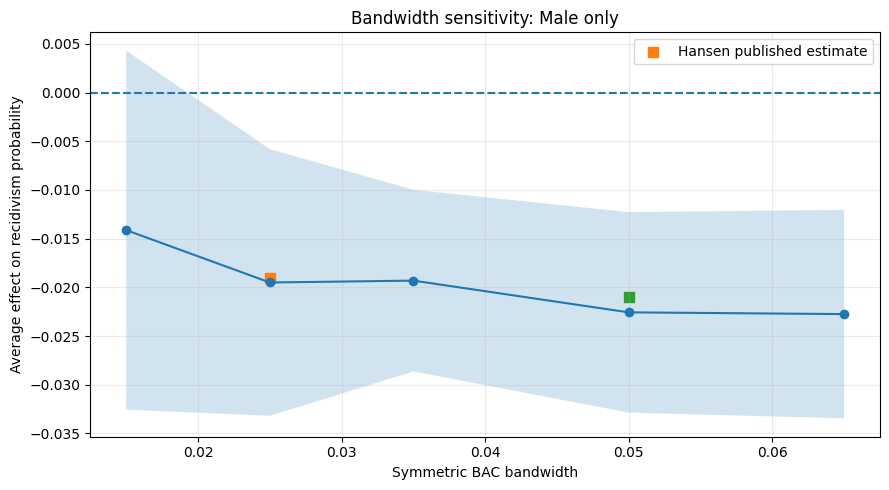

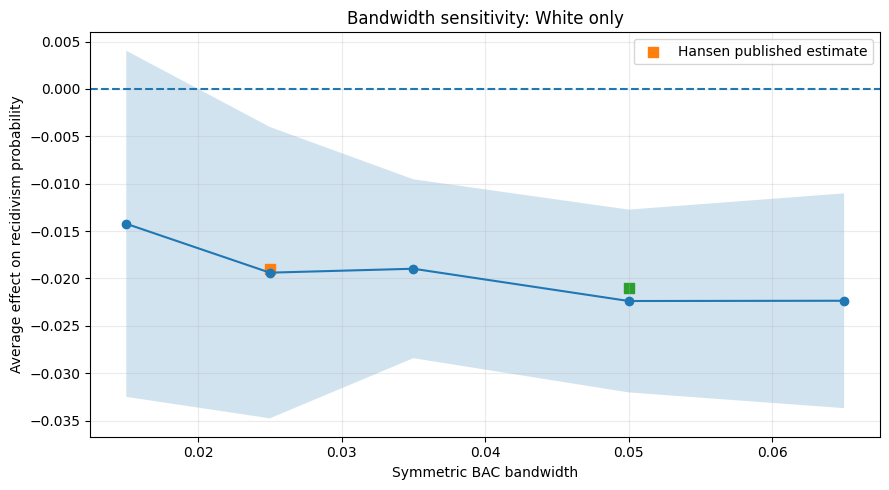

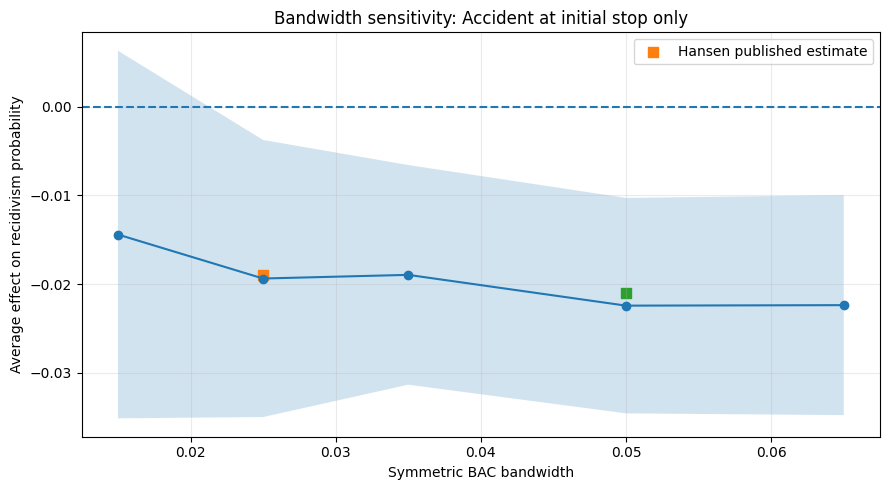

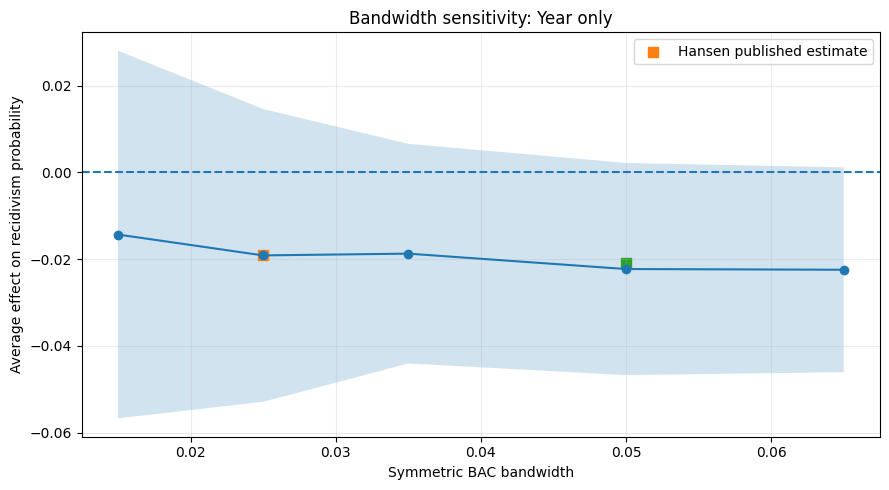


Approximate tests of equality with Hansen's estimates:
                           method  \
0   Conventional local-linear RDD   
1          Local-RD causal forest   
2          Local-RD causal forest   
3          Local-RD causal forest   
4          Local-RD causal forest   
5          Local-RD causal forest   
6   Conventional local-linear RDD   
7          Local-RD causal forest   
8          Local-RD causal forest   
9          Local-RD causal forest   
10         Local-RD causal forest   
11         Local-RD causal forest   
12  Nested local-RD causal forest   
13  Nested local-RD causal forest   
14  Nested local-RD causal forest   
15  Nested local-RD causal forest   
16  Nested local-RD causal forest   

                                        specification  bandwidth  \
0                                  Available controls      0.050   
1                                            Age only      0.050   
2                                           Male only      0.050   
3    

In [ ]:
"""
Hansen (2015) DUI Project: Revised Local-RD Causal Forest Analysis

Google Colab use:
1. Create a blank Colab notebook.
2. Upload this .py file and the modified Hansen CSV through the Files panel.
3. In one Colab cell, run:
       %run "/content/hansen_grf_causal_heterogeneity_colab.py"
4. The script creates tables and figures in output/ and a final ZIP archive.

The code contains detailed comments explaining each substantive step.
"""
# %% [markdown]

# %% [markdown]
# # Hansen (2015) DUI Project: Revised Local-RD Causal Forest Analysis
#
# This script implements the three changes requested after the presentation:
#
# 1. **Estimate heterogeneous treatment effects one characteristic at a time.**
#    The main single-characteristic models begin with age, then use prior DUI experience when that variable exists, followed by gender, race, accident involvement, and year. The script also reports nested models that add one characteristic at a time so the results can be compared as model complexity increases.
#
# 2. **Re-estimate the local-RD causal forest at several bandwidths around the 0.08 BAC cutoff.**
#    The default bandwidth grid is 0.015, 0.025, 0.035, 0.050, and 0.065 BAC points. The largest bandwidth stays below the separate 0.15 aggravated-DUI threshold.
#
# 3. **Test whether the revised estimates differ statistically from Hansen's published estimates.**
#    Hansen reports an effect of **−0.021 with SE 0.004** at bandwidth 0.05 and **−0.019 with SE 0.005** at bandwidth 0.025 for all tested drivers with controls. The script uses an approximate difference-in-estimates z-test based on both standard errors.
#
# A negative treatment effect means that crossing the 0.08 BAC threshold—and therefore facing the harsher DUI punishment regime—reduced the probability of four-year recidivism.
#
# The causal forest remains a **local-RD extension**. It is fitted only inside a chosen BAC window and uses local-linear RD terms as nuisance controls. The forest results should be interpreted as exploratory evidence about heterogeneity near the cutoff, while the conventional local-linear RDD remains the primary design-based benchmark.

# %% [markdown]
# ## 0. Install the causal-ML package

# %%
# ============================================================
# 0. INSTALL THE CAUSAL-ML PACKAGE
# ============================================================

# Import sys so the installer uses the same Python environment as this notebook.
import sys

# Import subprocess so Python can install EconML when needed.
import subprocess

# Try to import EconML before installing anything.
try:
    # Import EconML only to check whether it is already available.
    import econml
except ImportError:
    # Install the pinned EconML release used by this script.
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "econml==0.16.0"]
    )

# ============================================================

# %% [markdown]
# ## 1. Create the Colab folders and upload the modified data

# %%
# ============================================================
# 1. CREATE THE COLAB FOLDERS AND LOCATE/UPLOAD THE MODIFIED DATA
# ============================================================

# Import os so Python can create folders and work with paths.
import os

# Import glob so Python can automatically find an uploaded CSV file.
import glob

# Create the folder that will hold the standardized dataset.
os.makedirs("data", exist_ok=True)

# Create the folder that will hold result tables.
os.makedirs("output/tables", exist_ok=True)

# Create the folder that will hold result figures.
os.makedirs("output/figures", exist_ok=True)

# Set one standardized path used by the rest of the analysis.
DATA_PATH = "data/modified_hansen_data.csv"

# Check whether the standardized data file is already present.
if not os.path.exists(DATA_PATH):
    # Search the current Colab working directory for CSV files.
    available_csv_files = [
        path
        for path in glob.glob("*.csv")
        if os.path.isfile(path)
    ]

    # Automatically use the only CSV file when exactly one is present.
    if len(available_csv_files) == 1:
        # Read the detected CSV filename.
        detected_csv_path = available_csv_files[0]

        # Move the detected CSV to the standardized location.
        os.replace(detected_csv_path, DATA_PATH)

    # Prefer the specifically supplied modified Hansen filename when it is present.
    elif "modified_hansen_data (2).csv" in available_csv_files:
        # Move the supplied CSV to the standardized location.
        os.replace(
            "modified_hansen_data (2).csv",
            DATA_PATH,
        )

    # Open the Colab upload widget when the CSV cannot be identified automatically.
    else:
        try:
            # Import Colab's file-upload helper.
            from google.colab import files

            # Open the browser file picker.
            uploaded = files.upload()

            # Keep only uploaded files whose names end in .csv.
            uploaded_csv_files = [
                filename
                for filename in uploaded.keys()
                if filename.lower().endswith(".csv")
            ]

            # Stop when the user did not upload a CSV file.
            if len(uploaded_csv_files) == 0:
                raise FileNotFoundError(
                    "No CSV file was uploaded."
                )

            # Select the first uploaded CSV file.
            uploaded_csv_name = uploaded_csv_files[0]

            # Move the uploaded file to the standardized data path.
            os.replace(
                uploaded_csv_name,
                DATA_PATH,
            )
        except ImportError:
            # Give a clear instruction when the script is not running in Colab.
            raise FileNotFoundError(
                "Place the modified Hansen CSV in the same folder as this script "
                "or at data/modified_hansen_data.csv."
            )

# Print the path used by the rest of the script.
print("Dataset path:", DATA_PATH)

# ============================================================

# %% [markdown]
# ## 2. Import the analysis packages

# %%
# ============================================================
# 2. IMPORT THE ANALYSIS PACKAGES
# ============================================================

# Import warnings so nonessential warnings can be hidden.
import warnings

# Hide nonessential warnings to keep the script output readable.
warnings.filterwarnings("ignore")

# Import random so Python-level random operations can be reproduced.
import random

# Import shutil so the output folder can be compressed at the end.
import shutil

# Import NumPy for arrays and numerical calculations.
import numpy as np

# Import pandas for loading, cleaning, reshaping, and exporting data.
import pandas as pd

# Import matplotlib for figures.
import matplotlib.pyplot as plt

# Import statsmodels for conventional local-linear RDD estimates.
import statsmodels.api as sm

# Import a linear model for the causal-forest nuisance regressions.
from sklearn.linear_model import LinearRegression

# Import the normal distribution for p-values and difference tests.
from scipy.stats import norm

# Import EconML's honest causal-forest estimator.
from econml.dml import CausalForestDML

# ============================================================

# %% [markdown]
# ## 3. Set the main analysis options

# %%
# ============================================================
# 3. SET THE MAIN ANALYSIS OPTIONS
# ============================================================

# Set one random seed so repeated runs are reproducible.
RANDOM_SEED = 610

# Set the ordinary DUI cutoff studied in the main analysis.
PRIMARY_CUTOFF = 0.08

# Set Hansen's main bandwidth as the primary specification.
PRIMARY_BANDWIDTH = 0.05

# Use a rectangular kernel to match Hansen's main RDD specification.
PRIMARY_KERNEL = "rectangular"

# Define the four-year recidivism variable as the causal outcome.
OUTCOME_VARIABLE = "recidivism"

# Define the treatment indicator generated from the 0.08 BAC cutoff.
TREATMENT_VARIABLE = "dui"

# Define the bandwidths used for the conventional RDD and GRF sensitivity analysis.
BANDWIDTHS = [0.015, 0.025, 0.035, 0.050, 0.065]

# Set the number of trees used in the primary one-characteristic and nested forests.
PRIMARY_N_TREES = 600

# Set the number of trees used in each alternative-bandwidth forest.
BANDWIDTH_N_TREES = 300

# Require a reasonably large number of observations in each terminal leaf.
MIN_SAMPLES_LEAF = 100

# Use five folds when cross-fitting the nuisance models.
N_CROSSFIT_FOLDS = 5

# Turn the nested add-one-characteristic-at-a-time analysis on or off.
RUN_NESTED_MODELS = True

# Turn the full bandwidth-by-characteristic GRF grid on or off.
RUN_BANDWIDTH_GRFS = True

# Set whether Colab should automatically download the final ZIP archive.
DOWNLOAD_RESULTS_ZIP = False

# Set NumPy's random seed.
np.random.seed(RANDOM_SEED)

# Set Python's random seed.
random.seed(RANDOM_SEED)

# ============================================================

# %% [markdown]
# ## 4. Load and clean the modified Hansen data

# %%
# ============================================================
# 4. LOAD AND CLEAN THE MODIFIED HANSEN DATA
# ============================================================

# Load the uploaded CSV file into a pandas DataFrame.
df = pd.read_csv(DATA_PATH)

# Save the number of rows before cleaning.
original_rows = len(df)

# Standardize column names by converting them to lowercase and removing outside spaces.
df.columns = df.columns.str.lower().str.strip()

# Convert the two original alcohol readings to numeric values when they exist.
for alcohol_variable in ["alcohol1", "alcohol2"]:
    # Convert invalid strings to missing values.
    if alcohol_variable in df.columns:
        df[alcohol_variable] = pd.to_numeric(
            df[alcohol_variable],
            errors="coerce",
        )

# Create low_score from the lower of the two alcohol readings when low_score is absent.
if "low_score" not in df.columns:
    # Verify that both original alcohol readings are available.
    if not {"alcohol1", "alcohol2"}.issubset(df.columns):
        raise KeyError(
            "The dataset must contain low_score or both alcohol1 and alcohol2."
        )

    # Take the row-wise minimum because Hansen uses the lower BAC reading.
    df["low_score"] = df[["alcohol1", "alcohol2"]].min(axis=1)

# Convert low_score to numeric values.
df["low_score"] = pd.to_numeric(df["low_score"], errors="coerce")

# Convert integer BAC points such as 80 to decimal BAC such as 0.080.
if df["low_score"].max(skipna=True) > 1:
    # Divide by 1,000 when BAC is stored in thousandths.
    df["bac"] = df["low_score"] / 1000
else:
    # Keep BAC unchanged when it is already stored as a decimal.
    df["bac"] = df["low_score"]

# Define the variables that are always required.
required_variables = [
    "bac",
    "male",
    "white",
    "aged",
    "acc",
    "year",
    OUTCOME_VARIABLE,
]

# Stop with a clear message when a required variable is missing.
missing_required_variables = [
    variable
    for variable in required_variables
    if variable not in df.columns
]

# Raise an error when at least one required variable is absent.
if len(missing_required_variables) > 0:
    raise KeyError(
        "Missing required variables: "
        + ", ".join(missing_required_variables)
    )

# Convert all always-required analysis variables to numeric values.
for variable in required_variables:
    # Convert invalid strings to missing values.
    df[variable] = pd.to_numeric(df[variable], errors="coerce")

# List possible names for prior DUI experience in different versions of the data.
prior_aliases = [
    "prior",
    "prior_test",
    "prior_tests",
    "priors",
    "prior_dui",
    "prior_offense",
    "prior_offenses",
]

# Find the first prior-experience variable that exists.
PRIOR_VARIABLE = next(
    (
        variable
        for variable in prior_aliases
        if variable in df.columns
    ),
    None,
)

# Convert the optional prior-experience variable to numeric when it exists.
if PRIOR_VARIABLE is not None:
    # Convert invalid prior-experience values to missing.
    df[PRIOR_VARIABLE] = pd.to_numeric(
        df[PRIOR_VARIABLE],
        errors="coerce",
    )

# Build the list of variables that must be nonmissing.
nonmissing_variables = required_variables.copy()

# Add prior experience to the nonmissing list only when it is available.
if PRIOR_VARIABLE is not None:
    # Require observed prior experience so every specification uses a consistent sample.
    nonmissing_variables.append(PRIOR_VARIABLE)

# Drop rows missing any variable required by the analysis.
df = df.dropna(subset=nonmissing_variables).copy()

# Restrict the sample to Hansen's 1999 through 2007 study period.
df = df[
    (df["year"] >= 1999)
    & (df["year"] <= 2007)
].copy()

# Restrict the sample to drivers age 21 and older.
df = df[df["aged"] >= 21].copy()

# Reconstruct ordinary DUI treatment from the minimum BAC reading.
df[TREATMENT_VARIABLE] = (
    df["bac"] >= PRIMARY_CUTOFF
).astype(int)

# Reconstruct aggravated-DUI status for sample checks.
df["agg_dui"] = (
    df["bac"] >= 0.15
).astype(int)

# Create 0.001 BAC bins for clustered RDD standard errors.
df["bac_bin"] = df["bac"].round(3)

# Reset the index after all sample restrictions.
df = df.reset_index(drop=True)

# Create a stable row identifier for individual CATE exports.
df["row_id"] = np.arange(len(df))

# Print the raw and cleaned sample sizes.
print("Original rows:", original_rows)
print("Rows after cleaning:", len(df))

# Print the BAC range after cleaning.
print("BAC range:", df["bac"].min(), "to", df["bac"].max())

# Print the overall recidivism rate.
print(
    "Overall recidivism rate:",
    round(df[OUTCOME_VARIABLE].mean(), 4),
)

# Print whether prior DUI experience is available.
print("Prior-experience variable:", PRIOR_VARIABLE)

# Confirm that the core binary variables contain only zero and one.
for variable in [
    "male",
    "white",
    "acc",
    OUTCOME_VARIABLE,
    TREATMENT_VARIABLE,
    "agg_dui",
]:
    # Print the observed values for each binary variable.
    print(
        variable,
        "unique values:",
        sorted(df[variable].dropna().unique().tolist()),
    )

# ============================================================

# %% [markdown]
# ## 5. Define the characteristic order and model specifications

# %%
# ============================================================
# 5. DEFINE THE CHARACTERISTIC ORDER AND MODEL SPECIFICATIONS
# ============================================================

# Start the professor-requested ordering with age.
ordered_characteristics = [
    ("Age", "aged"),
]

# Add prior DUI experience immediately after age when it exists.
if PRIOR_VARIABLE is not None:
    # Use the detected prior-experience column in the model list.
    ordered_characteristics.append(
        ("Prior DUI experience", PRIOR_VARIABLE)
    )

# Add the remaining available predetermined characteristics.
ordered_characteristics.extend(
    [
        ("Male", "male"),
        ("White", "white"),
        ("Accident at initial stop", "acc"),
        ("Year", "year"),
    ]
)

# Create one specification for each characteristic by itself.
single_characteristic_specs = [
    {
        "specification": f"{label} only",
        "characteristic_label": label,
        "variables": [variable],
    }
    for label, variable in ordered_characteristics
]

# Create an empty list for nested specifications.
nested_specs = []

# Create an empty list that accumulates variables in the professor's preferred order.
cumulative_variables = []

# Add one characteristic at a time to create nested specifications.
for label, variable in ordered_characteristics:
    # Add the current variable to the cumulative model.
    cumulative_variables.append(variable)

    # Save the current nested specification.
    nested_specs.append(
        {
            "specification": " + ".join(
                [
                    characteristic_label
                    for characteristic_label, characteristic_variable
                    in ordered_characteristics
                    if characteristic_variable in cumulative_variables
                ]
            ),
            "variables": cumulative_variables.copy(),
        }
    )

# Print the one-characteristic-at-a-time specifications.
print("Single-characteristic specifications:")
for specification in single_characteristic_specs:
    # Print the model name and variables.
    print(
        " -",
        specification["specification"],
        specification["variables"],
    )

# Print the nested specifications.
print("\nNested specifications:")
for specification in nested_specs:
    # Print the model name and variables.
    print(
        " -",
        specification["specification"],
        specification["variables"],
    )

# ============================================================

# %% [markdown]
# ## 6. Define helper functions

# %%
# ============================================================
# 6. DEFINE HELPER FUNCTIONS
# ============================================================

# Define a function that creates rectangular or triangular kernel weights.
def make_kernel_weights(centered_bac, bandwidth, kernel="rectangular"):
    # Convert the centered BAC values to a NumPy array.
    centered_bac = np.asarray(centered_bac, dtype=float)

    # Return equal weights for the rectangular kernel.
    if kernel == "rectangular":
        return np.ones(len(centered_bac), dtype=float)

    # Calculate linearly declining weights for the triangular kernel.
    if kernel == "triangular":
        # Give the largest weight to observations nearest the cutoff.
        weights = 1 - np.abs(centered_bac) / bandwidth

        # Prevent exact zero weights at the bandwidth boundary.
        return np.clip(weights, 1e-6, None)

    # Stop when an unsupported kernel is supplied.
    raise ValueError(
        "kernel must be either 'rectangular' or 'triangular'."
    )


# Define a function that returns the controls available for the conventional RDD.
def get_rdd_controls():
    # Start with the predetermined controls available in every modified dataset.
    numeric_controls = [
        "male",
        "white",
        "aged",
        "acc",
    ]

    # Add prior DUI experience when it exists.
    if PRIOR_VARIABLE is not None:
        # Include prior experience as an additional predetermined control.
        numeric_controls.append(PRIOR_VARIABLE)

    # Treat year as a categorical fixed effect.
    categorical_controls = ["year"]

    # Return both control lists.
    return numeric_controls, categorical_controls


# Define a function that runs a local-linear RDD with side-specific slopes.
def run_local_linear_rdd(
    data,
    outcome,
    cutoff,
    bandwidth,
    treatment,
    add_controls=True,
    kernel="rectangular",
):
    # Keep observations inside the requested symmetric bandwidth.
    temp = data[
        (data["bac"] >= cutoff - bandwidth)
        & (data["bac"] <= cutoff + bandwidth)
    ].copy()

    # Stop when the local sample is too small.
    if len(temp) < 200:
        raise ValueError(
            f"Bandwidth {bandwidth} contains fewer than 200 observations."
        )

    # Stop when either side of the cutoff has no observations.
    if (
        (temp["bac"] < cutoff).sum() == 0
        or (temp["bac"] >= cutoff).sum() == 0
    ):
        raise ValueError(
            f"Bandwidth {bandwidth} does not contain both sides of the cutoff."
        )

    # Center the running variable at the cutoff.
    temp["bac_centered"] = temp["bac"] - cutoff

    # Reconstruct treatment from the requested cutoff.
    temp[treatment] = (
        temp["bac"] >= cutoff
    ).astype(int)

    # Create the treatment-by-running-variable interaction.
    temp["treatment_x_bac"] = (
        temp[treatment]
        * temp["bac_centered"]
    )

    # Begin the design matrix with the treatment jump and local slope terms.
    design_columns = [
        treatment,
        "bac_centered",
        "treatment_x_bac",
    ]

    # Retrieve the available predetermined controls.
    numeric_controls, categorical_controls = get_rdd_controls()

    # Add numeric predetermined controls when requested.
    if add_controls:
        # Extend the design matrix with all available numeric controls.
        design_columns = design_columns + numeric_controls

    # Select the numeric design columns.
    X_rdd = temp[design_columns].copy().reset_index(drop=True)

    # Add categorical fixed effects when controls are requested.
    if add_controls:
        # Loop through each categorical control.
        for categorical_variable in categorical_controls:
            # Create dummy variables and omit the first category.
            categorical_dummies = pd.get_dummies(
                temp[categorical_variable].astype(int),
                prefix=categorical_variable,
                drop_first=True,
                dtype=float,
            )

            # Join the dummy variables to the design matrix.
            X_rdd = pd.concat(
                [
                    X_rdd,
                    categorical_dummies.reset_index(drop=True),
                ],
                axis=1,
            )

    # Add an intercept.
    X_rdd = sm.add_constant(
        X_rdd,
        has_constant="add",
    )

    # Select the requested outcome.
    y_rdd = temp[outcome].astype(float).reset_index(drop=True)

    # Create the requested local kernel weights.
    weights = make_kernel_weights(
        temp["bac_centered"],
        bandwidth,
        kernel,
    )

    # Estimate the weighted local-linear regression.
    model = sm.WLS(
        y_rdd,
        X_rdd.astype(float),
        weights=weights,
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": temp["bac_bin"].reset_index(drop=True)
        },
    )

    # Extract the treatment coefficient.
    coefficient = float(model.params[treatment])

    # Extract the clustered standard error.
    standard_error = float(model.bse[treatment])

    # Calculate the two-sided p-value.
    p_value = float(model.pvalues[treatment])

    # Calculate the lower endpoint of the 95 percent confidence interval.
    ci_lower = coefficient - 1.96 * standard_error

    # Calculate the upper endpoint of the 95 percent confidence interval.
    ci_upper = coefficient + 1.96 * standard_error

    # Calculate the mean outcome below the cutoff in the same bandwidth.
    mean_below = float(
        temp.loc[
            temp["bac"] < cutoff,
            outcome,
        ].mean()
    )

    # Return the RDD results.
    return {
        "cutoff": cutoff,
        "bandwidth": bandwidth,
        "kernel": kernel,
        "coefficient": coefficient,
        "standard_error": standard_error,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "p_value": p_value,
        "mean_below_cutoff": mean_below,
        "observations": int(model.nobs),
        "bac_clusters": int(temp["bac_bin"].nunique()),
    }


# Define a function that builds fresh nuisance models for each forest.
def build_nuisance_models():
    # Use a linear outcome nuisance model to retain a local-linear adjustment.
    outcome_model = LinearRegression()

    # Use a linear treatment nuisance model for the sharp threshold indicator.
    treatment_model = LinearRegression()

    # Return both models.
    return outcome_model, treatment_model


# Define a helper that makes the tree count compatible with EconML inference.
def make_tree_count_compatible(n_estimators, subforest_size=4):
    # Round the requested tree count up to the nearest subforest multiple.
    compatible_count = int(
        np.ceil(n_estimators / subforest_size)
        * subforest_size
    )

    # Return the compatible number of trees.
    return compatible_count


# Define a function that fits one local-RD causal forest.
def fit_local_rd_causal_forest(
    data,
    cutoff,
    bandwidth,
    treatment,
    outcome,
    effect_modifiers,
    kernel="rectangular",
    n_estimators=600,
):
    # Keep only observations inside the requested local BAC window.
    local_data = data[
        (data["bac"] >= cutoff - bandwidth)
        & (data["bac"] <= cutoff + bandwidth)
    ].copy()

    # Stop when the local sample is too small.
    if len(local_data) < 500:
        raise ValueError(
            f"Bandwidth {bandwidth} contains fewer than 500 observations."
        )

    # Center BAC at the threshold.
    local_data["bac_centered"] = (
        local_data["bac"] - cutoff
    )

    # Reconstruct treatment from the threshold.
    local_data[treatment] = (
        local_data["bac"] >= cutoff
    ).astype(int)

    # Create the side-specific local-linear slope term.
    local_data["treatment_x_bac"] = (
        local_data[treatment].astype(float)
        * local_data["bac_centered"].astype(float)
    )

    # Create local kernel weights.
    local_data["kernel_weight"] = make_kernel_weights(
        local_data["bac_centered"],
        bandwidth,
        kernel,
    )

    # Select only the requested effect modifiers.
    X = local_data[
        effect_modifiers
    ].astype(float).copy()

    # Stop when any requested modifier is constant in the local sample.
    constant_modifiers = [
        variable
        for variable in effect_modifiers
        if X[variable].nunique() < 2
    ]

    # Raise a clear error when a modifier has no local variation.
    if len(constant_modifiers) > 0:
        raise ValueError(
            "Constant effect modifiers in local sample: "
            + ", ".join(constant_modifiers)
        )

    # Use the local-linear RD terms only as nuisance controls.
    W = local_data[
        [
            "bac_centered",
            "treatment_x_bac",
        ]
    ].astype(float).copy()

    # Select treatment as a numeric zero-one vector.
    T = local_data[
        treatment
    ].astype(float).to_numpy()

    # Select the recidivism outcome.
    Y = local_data[
        outcome
    ].astype(float).to_numpy()

    # Select the local kernel weights.
    sample_weight = local_data[
        "kernel_weight"
    ].astype(float).to_numpy()

    # Build fresh nuisance models.
    outcome_model, treatment_model = build_nuisance_models()

    # Make the number of trees compatible with subforest inference.
    compatible_tree_count = make_tree_count_compatible(
        n_estimators,
        subforest_size=4,
    )

    # Adapt the leaf size downward only when a very small local sample requires it.
    effective_min_leaf = min(
        MIN_SAMPLES_LEAF,
        max(20, len(local_data) // 100),
    )

    # Create the honest causal forest.
    causal_forest = CausalForestDML(
        model_y=outcome_model,
        model_t=treatment_model,
        discrete_outcome=False,
        discrete_treatment=False,
        cv=N_CROSSFIT_FOLDS,
        mc_iters=2,
        mc_agg="mean",
        drate=False,
        n_estimators=compatible_tree_count,
        criterion="mse",
        max_depth=None,
        min_samples_split=2 * effective_min_leaf,
        min_samples_leaf=effective_min_leaf,
        min_var_fraction_leaf=0.01,
        max_features=1.0,
        max_samples=0.45,
        honest=True,
        inference=True,
        fit_intercept=True,
        subforest_size=4,
        n_jobs=-1,
        random_state=RANDOM_SEED,
        verbose=0,
    )

    # Fit the local-RD causal forest.
    causal_forest.fit(
        Y,
        T,
        X=X,
        W=W,
        sample_weight=sample_weight,
        inference="auto",
    )

    # Estimate an individual CATE for every observation in the local sample.
    local_data["cate"] = causal_forest.effect(X)

    # Reset row indices so all returned objects align.
    local_data = local_data.reset_index(drop=True)

    # Reset the modifier-matrix index for later subgroup work.
    X = X.reset_index(drop=True)

    # Return the fitted forest and aligned local data.
    return causal_forest, local_data, X


# Define a helper that safely converts EconML output to a scalar.
def scalar_from_econml(value):
    # Convert arrays or scalars to one Python float.
    return float(np.asarray(value).squeeze())


# Define a function that summarizes one fitted forest.
def summarize_forest(
    causal_forest,
    local_data,
    X,
    specification,
    variables,
    bandwidth,
    model_type,
):
    # Estimate the forest's average treatment effect.
    ate = scalar_from_econml(
        causal_forest.ate(X)
    )

    # Estimate the 95 percent confidence interval for the average effect.
    ate_lower, ate_upper = causal_forest.ate_interval(
        X,
        alpha=0.05,
    )

    # Convert the lower endpoint to a scalar.
    ate_lower = scalar_from_econml(ate_lower)

    # Convert the upper endpoint to a scalar.
    ate_upper = scalar_from_econml(ate_upper)

    # Recover an approximate standard error from the 95 percent interval.
    ate_standard_error = (
        ate_upper - ate_lower
    ) / (2 * 1.96)

    # Calculate a two-sided normal p-value for a zero average effect.
    ate_p_value = 2 * norm.sf(
        abs(ate / ate_standard_error)
    )

    # Return one summary row.
    return {
        "model_type": model_type,
        "specification": specification,
        "variables": " + ".join(variables),
        "bandwidth": bandwidth,
        "forest_ate": ate,
        "forest_standard_error": ate_standard_error,
        "forest_ci_lower": ate_lower,
        "forest_ci_upper": ate_upper,
        "forest_p_value": ate_p_value,
        "observations": int(len(local_data)),
        "treated_share": float(
            local_data[TREATMENT_VARIABLE].mean()
        ),
        "outcome_mean": float(
            local_data[OUTCOME_VARIABLE].mean()
        ),
        "cate_mean": float(
            local_data["cate"].mean()
        ),
        "cate_standard_deviation": float(
            local_data["cate"].std()
        ),
        "cate_minimum": float(
            local_data["cate"].min()
        ),
        "cate_maximum": float(
            local_data["cate"].max()
        ),
    }


# Define a function that creates interpretable groups for one characteristic.
def create_characteristic_groups(local_data, variable):
    # Read the nonmissing values of the requested characteristic.
    values = local_data[variable].dropna()

    # Treat zero-one variables as binary groups.
    if set(values.unique()).issubset({0, 1}):
        # Return one group for zero and one group for one.
        return [
            ("0", local_data[variable] == 0, 0.0),
            ("1", local_data[variable] == 1, 1.0),
        ]

    # Treat year as one group per calendar year.
    if variable == "year":
        # Create a group for every observed year.
        return [
            (
                str(int(year_value)),
                local_data[variable] == year_value,
                float(year_value),
            )
            for year_value in sorted(values.unique())
        ]

    # Treat age as five-year bins.
    if variable == "aged":
        # Find the lowest five-year boundary.
        lower_boundary = int(
            np.floor(values.min() / 5) * 5
        )

        # Find the highest five-year boundary.
        upper_boundary = int(
            np.ceil((values.max() + 1) / 5) * 5
        )

        # Create five-year bin edges.
        age_edges = list(
            range(
                lower_boundary,
                upper_boundary + 5,
                5,
            )
        )

        # Assign every observation to an age bin.
        age_bins = pd.cut(
            local_data[variable],
            bins=age_edges,
            right=False,
            include_lowest=True,
        )

        # Create an empty group list.
        groups = []

        # Loop through observed age bins.
        for age_interval in age_bins.dropna().unique().sort_values():
            # Create a mask for the current age bin.
            age_mask = age_bins == age_interval

            # Calculate the group's mean age for plotting.
            mean_age = float(
                local_data.loc[
                    age_mask,
                    variable,
                ].mean()
            )

            # Create a readable age-bin label.
            age_label = (
                f"{int(age_interval.left)}-"
                f"{int(age_interval.right - 1)}"
            )

            # Store the age group.
            groups.append(
                (
                    age_label,
                    age_mask,
                    mean_age,
                )
            )

        # Return the five-year age groups.
        return groups

    # Treat a low-count integer variable such as prior tests as categories.
    if (
        np.allclose(values, np.round(values))
        and values.nunique() <= 10
    ):
        # Return one group for each observed integer value.
        return [
            (
                str(int(category_value)),
                local_data[variable] == category_value,
                float(category_value),
            )
            for category_value in sorted(values.unique())
        ]

    # Divide any other continuous characteristic into quartiles.
    quartile_groups = pd.qcut(
        local_data[variable],
        q=4,
        duplicates="drop",
    )

    # Create an empty list for continuous-variable groups.
    groups = []

    # Loop through the observed quartile intervals.
    for quartile_interval in quartile_groups.dropna().unique().sort_values():
        # Create the mask for the current quartile.
        quartile_mask = quartile_groups == quartile_interval

        # Calculate the mean characteristic value in the quartile.
        quartile_mean = float(
            local_data.loc[
                quartile_mask,
                variable,
            ].mean()
        )

        # Store the quartile group.
        groups.append(
            (
                str(quartile_interval),
                quartile_mask,
                quartile_mean,
            )
        )

    # Return the quartile groups.
    return groups


# Define a function that summarizes forest effects for one group.
def summarize_forest_group(
    causal_forest,
    X,
    local_data,
    mask,
    specification,
    variable,
    group_label,
    plot_value,
):
    # Convert the group mask to a Boolean NumPy array.
    mask_array = np.asarray(mask, dtype=bool)

    # Select the group's modifier rows.
    X_group = X.loc[mask_array].copy()

    # Skip empty groups.
    if len(X_group) == 0:
        return None

    # Estimate the group's average treatment effect.
    group_ate = scalar_from_econml(
        causal_forest.ate(X_group)
    )

    # Estimate the group's 95 percent confidence interval.
    group_lower, group_upper = causal_forest.ate_interval(
        X_group,
        alpha=0.05,
    )

    # Return one group summary row.
    return {
        "specification": specification,
        "variable": variable,
        "group": group_label,
        "plot_value": plot_value,
        "observations": int(mask_array.sum()),
        "treated_share": float(
            local_data.loc[
                mask_array,
                TREATMENT_VARIABLE,
            ].mean()
        ),
        "outcome_mean": float(
            local_data.loc[
                mask_array,
                OUTCOME_VARIABLE,
            ].mean()
        ),
        "forest_ate": group_ate,
        "forest_ci_lower": scalar_from_econml(
            group_lower
        ),
        "forest_ci_upper": scalar_from_econml(
            group_upper
        ),
    }


# Define a function that compares an estimate with Hansen's published estimate.
def compare_with_hansen(
    our_estimate,
    our_standard_error,
    hansen_estimate,
    hansen_standard_error,
):
    # Calculate the difference between the two estimates.
    difference = our_estimate - hansen_estimate

    # Calculate the standard error of the difference under independence.
    difference_standard_error = np.sqrt(
        our_standard_error ** 2
        + hansen_standard_error ** 2
    )

    # Calculate the z-statistic for equal effects.
    z_statistic = (
        difference
        / difference_standard_error
    )

    # Calculate the two-sided p-value.
    p_value = 2 * norm.sf(
        abs(z_statistic)
    )

    # Calculate the lower endpoint of the difference interval.
    difference_ci_lower = (
        difference
        - 1.96 * difference_standard_error
    )

    # Calculate the upper endpoint of the difference interval.
    difference_ci_upper = (
        difference
        + 1.96 * difference_standard_error
    )

    # Return the complete difference-test result.
    return {
        "difference_our_minus_hansen": difference,
        "difference_standard_error": difference_standard_error,
        "difference_ci_lower": difference_ci_lower,
        "difference_ci_upper": difference_ci_upper,
        "z_statistic": z_statistic,
        "p_value_equal_effects": p_value,
        "statistically_different_at_5pct": bool(
            p_value < 0.05
        ),
    }

# ============================================================

# %% [markdown]
# ## 7. Replicate the predetermined-covariate balance checks

# %%
# ============================================================
# 7. REPLICATE THE PREDETERMINED-COVARIATE BALANCE CHECKS
# ============================================================

# Define the predetermined characteristics available for balance testing.
balance_outcomes = {
    "Male": "male",
    "White": "white",
    "Age": "aged",
    "Accident": "acc",
}

# Add prior DUI experience to the balance checks when it exists.
if PRIOR_VARIABLE is not None:
    # Insert the optional prior-experience outcome.
    balance_outcomes[
        "Prior DUI experience"
    ] = PRIOR_VARIABLE

# Create an empty list for balance-check results.
balance_results = []

# Loop through each predetermined characteristic.
for characteristic_name, characteristic_variable in balance_outcomes.items():
    # Estimate a local-linear RDD with the characteristic as the outcome.
    balance_result = run_local_linear_rdd(
        data=df,
        outcome=characteristic_variable,
        cutoff=PRIMARY_CUTOFF,
        bandwidth=PRIMARY_BANDWIDTH,
        treatment=TREATMENT_VARIABLE,
        add_controls=False,
        kernel=PRIMARY_KERNEL,
    )

    # Add the readable characteristic name.
    balance_result[
        "characteristic"
    ] = characteristic_name

    # Store the result.
    balance_results.append(
        balance_result
    )

# Convert the results to a DataFrame.
balance_table = pd.DataFrame(
    balance_results
)

# Reorder the most useful columns.
balance_table = balance_table[
    [
        "characteristic",
        "coefficient",
        "standard_error",
        "ci_lower",
        "ci_upper",
        "p_value",
        "mean_below_cutoff",
        "observations",
        "bac_clusters",
    ]
]

# Save the balance table.
balance_table.to_csv(
    "output/tables/01_balance_checks.csv",
    index=False,
)

# Display the balance table.
print(
    "\nPredetermined-covariate balance checks at the 0.08 cutoff:"
)
print(
    balance_table.round(4)
)

# ============================================================

# %% [markdown]
# ## 8. Estimate the conventional local-linear RDD at every bandwidth

# %%
# ============================================================
# 8. ESTIMATE THE CONVENTIONAL LOCAL-LINEAR RDD AT EVERY BANDWIDTH
# ============================================================

# Create an empty list for the bandwidth-specific RDD estimates.
rdd_bandwidth_results = []

# Loop through each requested bandwidth.
for bandwidth in BANDWIDTHS:
    # Estimate Hansen's local-linear RDD with the available controls.
    rdd_result = run_local_linear_rdd(
        data=df,
        outcome=OUTCOME_VARIABLE,
        cutoff=PRIMARY_CUTOFF,
        bandwidth=bandwidth,
        treatment=TREATMENT_VARIABLE,
        add_controls=True,
        kernel=PRIMARY_KERNEL,
    )

    # Store the bandwidth-specific result.
    rdd_bandwidth_results.append(
        rdd_result
    )

# Convert the RDD results to a DataFrame.
rdd_bandwidth_table = pd.DataFrame(
    rdd_bandwidth_results
)

# Save the RDD bandwidth table.
rdd_bandwidth_table.to_csv(
    "output/tables/02_rdd_bandwidth_results.csv",
    index=False,
)

# Display the RDD bandwidth table.
print(
    "\nConventional local-linear RDD estimates across bandwidths:"
)
print(
    rdd_bandwidth_table.round(4)
)

# ============================================================

# %% [markdown]
# ## 9. Plot the conventional RDD at the main bandwidth

# %%
# ============================================================
# 9. PLOT THE CONVENTIONAL RDD AT THE MAIN BANDWIDTH
# ============================================================

# Keep observations inside the primary bandwidth.
rdd_plot_data = df[
    (df["bac"] >= PRIMARY_CUTOFF - PRIMARY_BANDWIDTH)
    & (df["bac"] <= PRIMARY_CUTOFF + PRIMARY_BANDWIDTH)
].copy()

# Calculate the mean recidivism rate in each observed BAC value.
rdd_bins = (
    rdd_plot_data
    .groupby("bac", as_index=False)
    .agg(
        recidivism_rate=(
            OUTCOME_VARIABLE,
            "mean",
        ),
        observations=(
            OUTCOME_VARIABLE,
            "size",
        ),
    )
    .sort_values("bac")
)

# Separate bins below the cutoff.
rdd_bins_below = rdd_bins[
    rdd_bins["bac"] < PRIMARY_CUTOFF
].copy()

# Separate bins at or above the cutoff.
rdd_bins_above = rdd_bins[
    rdd_bins["bac"] >= PRIMARY_CUTOFF
].copy()

# Fit a linear trend below the cutoff.
below_line = np.polyfit(
    rdd_bins_below["bac"],
    rdd_bins_below["recidivism_rate"],
    1,
)

# Fit a linear trend above the cutoff.
above_line = np.polyfit(
    rdd_bins_above["bac"],
    rdd_bins_above["recidivism_rate"],
    1,
)

# Create a new figure.
plt.figure(figsize=(10, 6))

# Plot the binned recidivism means.
plt.scatter(
    rdd_bins["bac"],
    rdd_bins["recidivism_rate"],
    s=25,
    alpha=0.75,
)

# Plot the fitted trend below the cutoff.
plt.plot(
    rdd_bins_below["bac"],
    np.polyval(
        below_line,
        rdd_bins_below["bac"],
    ),
    linewidth=2,
)

# Plot the fitted trend above the cutoff.
plt.plot(
    rdd_bins_above["bac"],
    np.polyval(
        above_line,
        rdd_bins_above["bac"],
    ),
    linewidth=2,
)

# Draw the 0.08 cutoff.
plt.axvline(
    PRIMARY_CUTOFF,
    linestyle="--",
    linewidth=1.5,
)

# Add a title.
plt.title(
    "Recidivism around the 0.08 BAC cutoff"
)

# Label the horizontal axis.
plt.xlabel(
    "Minimum BAC reading"
)

# Label the vertical axis.
plt.ylabel(
    "Mean four-year recidivism rate"
)

# Add a light grid.
plt.grid(alpha=0.25)

# Prevent labels from being cut off.
plt.tight_layout()

# Save the figure.
plt.savefig(
    "output/figures/01_rdd_recidivism_cutoff.png",
    dpi=300,
    bbox_inches="tight",
)

# Display the figure.
plt.show()

# ============================================================

# %% [markdown]
# ## 10. Record Hansen's published benchmark estimates

# %%
# ============================================================
# 10. RECORD HANSEN'S PUBLISHED BENCHMARK ESTIMATES
# ============================================================

# Create a table using Hansen's Table 3 estimates for all tested drivers with controls.
hansen_benchmark_table = pd.DataFrame(
    [
        {
            "bandwidth": 0.050,
            "hansen_estimate": -0.021,
            "hansen_standard_error": 0.004,
            "hansen_observations": 95111,
            "source": "Hansen (2015), Table 3, Panel A, all tested drivers",
        },
        {
            "bandwidth": 0.025,
            "hansen_estimate": -0.019,
            "hansen_standard_error": 0.005,
            "hansen_observations": 49396,
            "source": "Hansen (2015), Table 3, Panel B, all tested drivers",
        },
    ]
)

# Save the Hansen benchmark table.
hansen_benchmark_table.to_csv(
    "output/tables/03_hansen_benchmarks.csv",
    index=False,
)

# Display the Hansen benchmark table.
print(
    "\nHansen benchmark estimates used in the difference tests:"
)
print(
    hansen_benchmark_table
)

# ============================================================

# %% [markdown]
# ## 11. Fit the primary one-characteristic-at-a-time causal forests

# %%
# ============================================================
# 11. FIT THE PRIMARY ONE-CHARACTERISTIC-AT-A-TIME CAUSAL FORESTS
# ============================================================

# Create a dictionary that stores each fitted single-characteristic forest.
single_forest_cache = {}

# Create an empty list for the primary single-characteristic summaries.
single_primary_results = []

# Create an empty list for individual CATE estimates.
single_individual_cates = []

# Loop through each one-characteristic specification.
for specification in single_characteristic_specs:
    # Read the specification name.
    specification_name = specification[
        "specification"
    ]

    # Read the single effect-modifier variable.
    specification_variables = specification[
        "variables"
    ]

    # Print progress because forest estimation can take several minutes.
    print(
        f"\nFitting primary forest: {specification_name}"
    )

    # Fit the local-RD causal forest at the primary bandwidth.
    fitted_forest, local_data, X_local = fit_local_rd_causal_forest(
        data=df,
        cutoff=PRIMARY_CUTOFF,
        bandwidth=PRIMARY_BANDWIDTH,
        treatment=TREATMENT_VARIABLE,
        outcome=OUTCOME_VARIABLE,
        effect_modifiers=specification_variables,
        kernel=PRIMARY_KERNEL,
        n_estimators=PRIMARY_N_TREES,
    )

    # Store the fitted objects for reuse in profiles and bandwidth analysis.
    single_forest_cache[
        (
            specification_name,
            PRIMARY_BANDWIDTH,
        )
    ] = (
        fitted_forest,
        local_data,
        X_local,
    )

    # Summarize the forest's average effect.
    forest_summary = summarize_forest(
        causal_forest=fitted_forest,
        local_data=local_data,
        X=X_local,
        specification=specification_name,
        variables=specification_variables,
        bandwidth=PRIMARY_BANDWIDTH,
        model_type="Single characteristic",
    )

    # Store the primary summary.
    single_primary_results.append(
        forest_summary
    )

    # Create a compact individual-CATE export for this specification.
    cate_export = local_data[
        [
            "row_id",
            "bac",
            OUTCOME_VARIABLE,
            TREATMENT_VARIABLE,
            "cate",
        ]
        + specification_variables
    ].copy()

    # Add the specification name to the individual-CATE export.
    cate_export[
        "specification"
    ] = specification_name

    # Add the bandwidth to the individual-CATE export.
    cate_export[
        "bandwidth"
    ] = PRIMARY_BANDWIDTH

    # Store the individual-CATE rows.
    single_individual_cates.append(
        cate_export
    )

# Convert the primary summaries to a DataFrame.
single_primary_table = pd.DataFrame(
    single_primary_results
)

# Combine the individual-CATE exports.
single_individual_cate_table = pd.concat(
    single_individual_cates,
    ignore_index=True,
)

# Save the primary one-characteristic results.
single_primary_table.to_csv(
    "output/tables/04_single_characteristic_primary_grf.csv",
    index=False,
)

# Save the primary individual CATE estimates.
single_individual_cate_table.to_csv(
    "output/tables/05_single_characteristic_individual_cates.csv",
    index=False,
)

# Display the primary one-characteristic results.
print(
    "\nPrimary one-characteristic-at-a-time GRF results:"
)
print(
    single_primary_table.round(4)
)

# ============================================================

# %% [markdown]
# ## 12. Fit nested models that add one characteristic at a time

# %%
# ============================================================
# 12. FIT NESTED MODELS THAT ADD ONE CHARACTERISTIC AT A TIME
# ============================================================

# Create an empty list for nested-model summaries.
nested_primary_results = []

# Create a dictionary that can store nested fitted forests.
nested_forest_cache = {}

# Run nested models only when the option is turned on.
if RUN_NESTED_MODELS:
    # Loop through each nested specification.
    for specification in nested_specs:
        # Read the nested specification name.
        specification_name = specification[
            "specification"
        ]

        # Read the accumulated modifier list.
        specification_variables = specification[
            "variables"
        ]

        # Print progress.
        print(
            f"\nFitting nested forest: {specification_name}"
        )

        # Fit the local-RD causal forest.
        fitted_forest, local_data, X_local = fit_local_rd_causal_forest(
            data=df,
            cutoff=PRIMARY_CUTOFF,
            bandwidth=PRIMARY_BANDWIDTH,
            treatment=TREATMENT_VARIABLE,
            outcome=OUTCOME_VARIABLE,
            effect_modifiers=specification_variables,
            kernel=PRIMARY_KERNEL,
            n_estimators=PRIMARY_N_TREES,
        )

        # Store the fitted nested model.
        nested_forest_cache[
            specification_name
        ] = (
            fitted_forest,
            local_data,
            X_local,
        )

        # Summarize the nested forest.
        forest_summary = summarize_forest(
            causal_forest=fitted_forest,
            local_data=local_data,
            X=X_local,
            specification=specification_name,
            variables=specification_variables,
            bandwidth=PRIMARY_BANDWIDTH,
            model_type="Nested add-one-at-a-time",
        )

        # Store the nested-model summary.
        nested_primary_results.append(
            forest_summary
        )

# Convert nested results to a DataFrame.
nested_primary_table = pd.DataFrame(
    nested_primary_results
)

# Save nested results when at least one model was estimated.
if len(nested_primary_table) > 0:
    # Export the nested-model table.
    nested_primary_table.to_csv(
        "output/tables/06_nested_primary_grf.csv",
        index=False,
    )

    # Display the nested-model results.
    print(
        "\nNested add-one-characteristic-at-a-time GRF results:"
    )
    print(
        nested_primary_table.round(4)
    )

# ============================================================

# %% [markdown]
# ## 13. Plot the primary average effects across specifications

# %%
# ============================================================
# 13. PLOT THE PRIMARY AVERAGE EFFECTS ACROSS SPECIFICATIONS
# ============================================================

# Create a plotting copy of the single-characteristic results.
primary_plot_table = single_primary_table.copy()

# Calculate the lower error-bar length.
primary_plot_table[
    "lower_error"
] = (
    primary_plot_table["forest_ate"]
    - primary_plot_table["forest_ci_lower"]
)

# Calculate the upper error-bar length.
primary_plot_table[
    "upper_error"
] = (
    primary_plot_table["forest_ci_upper"]
    - primary_plot_table["forest_ate"]
)

# Create asymmetric confidence-interval errors.
primary_errors = np.vstack(
    [
        primary_plot_table["lower_error"],
        primary_plot_table["upper_error"],
    ]
)

# Create a new figure.
plt.figure(figsize=(10, 6))

# Plot each average forest effect with its 95 percent interval.
plt.errorbar(
    primary_plot_table["forest_ate"],
    primary_plot_table["specification"],
    xerr=primary_errors,
    fmt="o",
    capsize=4,
)

# Draw a zero-effect reference line.
plt.axvline(
    0,
    linestyle="--",
    linewidth=1.5,
)

# Draw Hansen's primary bandwidth estimate.
plt.axvline(
    -0.021,
    linestyle=":",
    linewidth=1.5,
    label="Hansen estimate at bandwidth 0.05",
)

# Add a title.
plt.title(
    "Primary GRF average effects: one characteristic at a time"
)

# Label the horizontal axis.
plt.xlabel(
    "Effect on four-year recidivism probability"
)

# Label the vertical axis.
plt.ylabel(
    "GRF specification"
)

# Add a legend.
plt.legend()

# Add a light horizontal grid.
plt.grid(
    axis="x",
    alpha=0.25,
)

# Prevent labels from being cut off.
plt.tight_layout()

# Save the figure.
plt.savefig(
    "output/figures/02_primary_single_characteristic_ates.png",
    dpi=300,
    bbox_inches="tight",
)

# Display the figure.
plt.show()

# ============================================================

# %% [markdown]
# ## 14. Estimate interpretable treatment-effect profiles for each characteristic

# %%
# ============================================================
# 14. ESTIMATE INTERPRETABLE TREATMENT-EFFECT PROFILES
# ============================================================

# Create an empty list for all characteristic-profile rows.
profile_results = []

# Loop through the one-characteristic specifications.
for specification in single_characteristic_specs:
    # Read the specification name.
    specification_name = specification[
        "specification"
    ]

    # Read the single characteristic variable.
    characteristic_variable = specification[
        "variables"
    ][0]

    # Retrieve the already fitted primary forest.
    fitted_forest, local_data, X_local = single_forest_cache[
        (
            specification_name,
            PRIMARY_BANDWIDTH,
        )
    ]

    # Create interpretable groups for the characteristic.
    characteristic_groups = create_characteristic_groups(
        local_data,
        characteristic_variable,
    )

    # Loop through the characteristic groups.
    for group_label, group_mask, plot_value in characteristic_groups:
        # Summarize the group's forest effect.
        group_summary = summarize_forest_group(
            causal_forest=fitted_forest,
            X=X_local,
            local_data=local_data,
            mask=group_mask,
            specification=specification_name,
            variable=characteristic_variable,
            group_label=group_label,
            plot_value=plot_value,
        )

        # Store nonempty group results.
        if group_summary is not None:
            # Append the valid group summary.
            profile_results.append(
                group_summary
            )

# Convert all profile results to a DataFrame.
characteristic_profile_table = pd.DataFrame(
    profile_results
)

# Save the characteristic-profile table.
characteristic_profile_table.to_csv(
    "output/tables/07_characteristic_effect_profiles.csv",
    index=False,
)

# Display the characteristic-profile table.
print(
    "\nInterpretable treatment-effect profiles:"
)
print(
    characteristic_profile_table.round(4)
)

# ============================================================

# %% [markdown]
# ## 15. Plot the treatment-effect profile for each characteristic

# %%
# ============================================================
# 15. PLOT THE TREATMENT-EFFECT PROFILE FOR EACH CHARACTERISTIC
# ============================================================

# Loop through each one-characteristic specification.
for specification in single_characteristic_specs:
    # Read the specification name.
    specification_name = specification[
        "specification"
    ]

    # Read the characteristic variable.
    characteristic_variable = specification[
        "variables"
    ][0]

    # Keep only profile rows from the current specification.
    plot_data = characteristic_profile_table[
        characteristic_profile_table["specification"]
        == specification_name
    ].copy()

    # Sort groups by their numeric plotting value.
    plot_data = plot_data.sort_values(
        "plot_value"
    )

    # Calculate lower error-bar lengths.
    lower_error = (
        plot_data["forest_ate"]
        - plot_data["forest_ci_lower"]
    )

    # Calculate upper error-bar lengths.
    upper_error = (
        plot_data["forest_ci_upper"]
        - plot_data["forest_ate"]
    )

    # Stack the asymmetric errors.
    profile_errors = np.vstack(
        [
            lower_error,
            upper_error,
        ]
    )

    # Create a new figure.
    plt.figure(figsize=(9, 5))

    # Plot profile effects with 95 percent intervals.
    plt.errorbar(
        plot_data["plot_value"],
        plot_data["forest_ate"],
        yerr=profile_errors,
        fmt="o-",
        capsize=4,
    )

    # Draw a zero-effect reference line.
    plt.axhline(
        0,
        linestyle="--",
        linewidth=1.5,
    )

    # Add a title.
    plt.title(
        f"Estimated DUI effect by {specification_name}"
    )

    # Label the horizontal axis.
    plt.xlabel(
        characteristic_variable
    )

    # Label the vertical axis.
    plt.ylabel(
        "Effect on four-year recidivism probability"
    )

    # Use readable group labels on the horizontal axis.
    plt.xticks(
        plot_data["plot_value"],
        plot_data["group"],
        rotation=45,
        ha="right",
    )

    # Add a light grid.
    plt.grid(alpha=0.25)

    # Prevent labels from being cut off.
    plt.tight_layout()

    # Create a safe filename from the variable name.
    safe_variable_name = (
        characteristic_variable
        .replace(" ", "_")
        .replace("/", "_")
    )

    # Save the characteristic-profile figure.
    plt.savefig(
        f"output/figures/03_profile_{safe_variable_name}.png",
        dpi=300,
        bbox_inches="tight",
    )

    # Display the figure.
    plt.show()

# ============================================================

# %% [markdown]
# ## 16. Run the one-characteristic causal forests at multiple bandwidths

# %%
# ============================================================
# 16. RUN THE ONE-CHARACTERISTIC CAUSAL FORESTS AT MULTIPLE BANDWIDTHS
# ============================================================

# Create an empty list for bandwidth-by-characteristic GRF results.
bandwidth_grf_results = []

# Run the full bandwidth grid only when the option is turned on.
if RUN_BANDWIDTH_GRFS:
    # Loop through each one-characteristic specification.
    for specification in single_characteristic_specs:
        # Read the specification name.
        specification_name = specification[
            "specification"
        ]

        # Read the single effect modifier.
        specification_variables = specification[
            "variables"
        ]

        # Loop through each requested bandwidth.
        for bandwidth in BANDWIDTHS:
            # Print progress.
            print(
                f"\nBandwidth GRF: {specification_name}, "
                f"bandwidth={bandwidth:.3f}"
            )

            # Reuse the primary fitted forest when the bandwidth matches 0.05.
            if np.isclose(
                bandwidth,
                PRIMARY_BANDWIDTH,
            ):
                # Retrieve the cached primary fit.
                fitted_forest, local_data, X_local = single_forest_cache[
                    (
                        specification_name,
                        PRIMARY_BANDWIDTH,
                    )
                ]
            else:
                # Fit the one-characteristic forest at the alternative bandwidth.
                fitted_forest, local_data, X_local = fit_local_rd_causal_forest(
                    data=df,
                    cutoff=PRIMARY_CUTOFF,
                    bandwidth=bandwidth,
                    treatment=TREATMENT_VARIABLE,
                    outcome=OUTCOME_VARIABLE,
                    effect_modifiers=specification_variables,
                    kernel=PRIMARY_KERNEL,
                    n_estimators=BANDWIDTH_N_TREES,
                )

                # Store the alternative-bandwidth fit for optional reuse.
                single_forest_cache[
                    (
                        specification_name,
                        bandwidth,
                    )
                ] = (
                    fitted_forest,
                    local_data,
                    X_local,
                )

            # Summarize the bandwidth-specific forest.
            bandwidth_summary = summarize_forest(
                causal_forest=fitted_forest,
                local_data=local_data,
                X=X_local,
                specification=specification_name,
                variables=specification_variables,
                bandwidth=bandwidth,
                model_type="Single characteristic bandwidth sensitivity",
            )

            # Store the bandwidth-specific result.
            bandwidth_grf_results.append(
                bandwidth_summary
            )

# Convert the bandwidth results to a DataFrame.
bandwidth_grf_table = pd.DataFrame(
    bandwidth_grf_results
)

# Save the bandwidth results.
if len(bandwidth_grf_table) > 0:
    # Export the complete bandwidth-by-characteristic table.
    bandwidth_grf_table.to_csv(
        "output/tables/08_grf_bandwidth_sensitivity.csv",
        index=False,
    )

    # Display the complete sensitivity table.
    print(
        "\nGRF bandwidth sensitivity results:"
    )
    print(
        bandwidth_grf_table.round(4)
    )

# ============================================================

# %% [markdown]
# ## 17. Plot the bandwidth sensitivity for each characteristic

# %%
# ============================================================
# 17. PLOT THE BANDWIDTH SENSITIVITY FOR EACH CHARACTERISTIC
# ============================================================

# Create figures only when bandwidth forests were estimated.
if len(bandwidth_grf_table) > 0:
    # Loop through each one-characteristic specification.
    for specification in single_characteristic_specs:
        # Read the specification name.
        specification_name = specification[
            "specification"
        ]

        # Read the characteristic variable.
        characteristic_variable = specification[
            "variables"
        ][0]

        # Keep only rows from the current specification.
        plot_data = bandwidth_grf_table[
            bandwidth_grf_table["specification"]
            == specification_name
        ].copy()

        # Sort the rows by bandwidth.
        plot_data = plot_data.sort_values(
            "bandwidth"
        )

        # Create a new figure.
        plt.figure(figsize=(9, 5))

        # Plot the average forest effect at each bandwidth.
        plt.plot(
            plot_data["bandwidth"],
            plot_data["forest_ate"],
            marker="o",
        )

        # Shade the 95 percent confidence interval.
        plt.fill_between(
            plot_data["bandwidth"],
            plot_data["forest_ci_lower"],
            plot_data["forest_ci_upper"],
            alpha=0.2,
        )

        # Draw a zero-effect reference line.
        plt.axhline(
            0,
            linestyle="--",
            linewidth=1.5,
        )

        # Add Hansen's 0.025 estimate as a comparison point.
        plt.scatter(
            [0.025],
            [-0.019],
            marker="s",
            s=60,
            label="Hansen published estimate",
        )

        # Add Hansen's 0.05 estimate as a comparison point.
        plt.scatter(
            [0.050],
            [-0.021],
            marker="s",
            s=60,
        )

        # Add a title.
        plt.title(
            f"Bandwidth sensitivity: {specification_name}"
        )

        # Label the horizontal axis.
        plt.xlabel(
            "Symmetric BAC bandwidth"
        )

        # Label the vertical axis.
        plt.ylabel(
            "Average effect on recidivism probability"
        )

        # Add a legend.
        plt.legend()

        # Add a light grid.
        plt.grid(alpha=0.25)

        # Prevent labels from being cut off.
        plt.tight_layout()

        # Create a safe filename.
        safe_variable_name = (
            characteristic_variable
            .replace(" ", "_")
            .replace("/", "_")
        )

        # Save the bandwidth-sensitivity figure.
        plt.savefig(
            f"output/figures/04_bandwidth_{safe_variable_name}.png",
            dpi=300,
            bbox_inches="tight",
        )

        # Display the figure.
        plt.show()

# ============================================================

# %% [markdown]
# ## 18. Test whether the revised estimates differ from Hansen's estimates
#
# The correct comparison is **not** a one-sample t-test on the individual predicted CATE values. Those CATEs are model predictions and are not independent observations.
#
# Instead, the notebook compares two estimated average effects:
#
# \[
# z=
# \frac{\widehat{\tau}_{ours}-\widehat{\tau}_{Hansen}}
# {\sqrt{SE(\widehat{\tau}_{ours})^2+SE(\widehat{\tau}_{Hansen})^2}}.
# \]
#
# This is an approximate test that treats the two estimates as independent. Because the modified dataset may overlap with or be derived from Hansen's original data, the covariance between estimates is unknown. Therefore, the p-values should be described as an **approximate benchmark comparison**, not a definitive independent-sample test.

# %%
# ============================================================
# 18. TEST WHETHER THE REVISED ESTIMATES DIFFER FROM HANSEN'S ESTIMATES
# ============================================================

# Create an empty list for difference-test results.
mean_test_results = []

# Loop through Hansen's two published bandwidth benchmarks.
for _, hansen_row in hansen_benchmark_table.iterrows():
    # Read the benchmark bandwidth.
    benchmark_bandwidth = float(
        hansen_row["bandwidth"]
    )

    # Read Hansen's point estimate.
    hansen_estimate = float(
        hansen_row["hansen_estimate"]
    )

    # Read Hansen's standard error.
    hansen_standard_error = float(
        hansen_row["hansen_standard_error"]
    )

    # Select our conventional RDD result at the matching bandwidth.
    matching_rdd = rdd_bandwidth_table[
        np.isclose(
            rdd_bandwidth_table["bandwidth"],
            benchmark_bandwidth,
        )
    ].iloc[0]

    # Compare our conventional RDD estimate with Hansen's estimate.
    rdd_test = compare_with_hansen(
        our_estimate=float(
            matching_rdd["coefficient"]
        ),
        our_standard_error=float(
            matching_rdd["standard_error"]
        ),
        hansen_estimate=hansen_estimate,
        hansen_standard_error=hansen_standard_error,
    )

    # Store the conventional RDD comparison.
    mean_test_results.append(
        {
            "method": "Conventional local-linear RDD",
            "specification": "Available controls",
            "bandwidth": benchmark_bandwidth,
            "our_estimate": float(
                matching_rdd["coefficient"]
            ),
            "our_standard_error": float(
                matching_rdd["standard_error"]
            ),
            "hansen_estimate": hansen_estimate,
            "hansen_standard_error": hansen_standard_error,
            **rdd_test,
        }
    )

    # Select single-characteristic GRF results at the matching bandwidth.
    matching_single_grfs = bandwidth_grf_table[
        np.isclose(
            bandwidth_grf_table["bandwidth"],
            benchmark_bandwidth,
        )
    ].copy()

    # Loop through the matching one-characteristic GRFs.
    for _, grf_row in matching_single_grfs.iterrows():
        # Compare the GRF average effect with Hansen's estimate.
        grf_test = compare_with_hansen(
            our_estimate=float(
                grf_row["forest_ate"]
            ),
            our_standard_error=float(
                grf_row["forest_standard_error"]
            ),
            hansen_estimate=hansen_estimate,
            hansen_standard_error=hansen_standard_error,
        )

        # Store the GRF comparison.
        mean_test_results.append(
            {
                "method": "Local-RD causal forest",
                "specification": grf_row[
                    "specification"
                ],
                "bandwidth": benchmark_bandwidth,
                "our_estimate": float(
                    grf_row["forest_ate"]
                ),
                "our_standard_error": float(
                    grf_row["forest_standard_error"]
                ),
                "hansen_estimate": hansen_estimate,
                "hansen_standard_error": hansen_standard_error,
                **grf_test,
            }
        )

# Add nested primary-bandwidth comparisons when nested models were estimated.
if len(nested_primary_table) > 0:
    # Select Hansen's primary 0.05 benchmark row.
    hansen_primary_row = hansen_benchmark_table[
        np.isclose(
            hansen_benchmark_table["bandwidth"],
            PRIMARY_BANDWIDTH,
        )
    ].iloc[0]

    # Loop through each nested primary model.
    for _, nested_row in nested_primary_table.iterrows():
        # Compare the nested GRF average effect with Hansen's estimate.
        nested_test = compare_with_hansen(
            our_estimate=float(
                nested_row["forest_ate"]
            ),
            our_standard_error=float(
                nested_row["forest_standard_error"]
            ),
            hansen_estimate=float(
                hansen_primary_row["hansen_estimate"]
            ),
            hansen_standard_error=float(
                hansen_primary_row[
                    "hansen_standard_error"
                ]
            ),
        )

        # Store the nested-model comparison.
        mean_test_results.append(
            {
                "method": "Nested local-RD causal forest",
                "specification": nested_row[
                    "specification"
                ],
                "bandwidth": PRIMARY_BANDWIDTH,
                "our_estimate": float(
                    nested_row["forest_ate"]
                ),
                "our_standard_error": float(
                    nested_row["forest_standard_error"]
                ),
                "hansen_estimate": float(
                    hansen_primary_row["hansen_estimate"]
                ),
                "hansen_standard_error": float(
                    hansen_primary_row[
                        "hansen_standard_error"
                    ]
                ),
                **nested_test,
            }
        )

# Convert all difference tests to a DataFrame.
mean_test_table = pd.DataFrame(
    mean_test_results
)

# Save the difference-test table.
mean_test_table.to_csv(
    "output/tables/09_mean_tests_vs_hansen.csv",
    index=False,
)

# Display the difference-test table.
print(
    "\nApproximate tests of equality with Hansen's estimates:"
)
print(
    mean_test_table.round(4)
)

# Print a simple interpretation guide.
print(
    "\nInterpretation: p_value_equal_effects below 0.05 means "
    "the two estimated effects are statistically different "
    "under the independence approximation."
)

# ============================================================

# %% [markdown]
# ## 19. Create a concise interpretation table

# %%
# ============================================================
# 19. CREATE A CONCISE INTERPRETATION TABLE
# ============================================================

# Select the most presentation-ready columns from the primary one-characteristic results.
presentation_table = single_primary_table[
    [
        "specification",
        "bandwidth",
        "forest_ate",
        "forest_standard_error",
        "forest_ci_lower",
        "forest_ci_upper",
        "forest_p_value",
        "observations",
        "cate_standard_deviation",
    ]
].copy()

# Convert the average treatment effect to percentage points.
presentation_table[
    "effect_percentage_points"
] = (
    100
    * presentation_table["forest_ate"]
)

# Create a plain-language direction label.
presentation_table[
    "direction"
] = np.where(
    presentation_table["forest_ate"] < 0,
    "Lower recidivism after crossing 0.08",
    "Higher recidivism after crossing 0.08",
)

# Create a statistical-significance label.
presentation_table[
    "significant_at_5pct"
] = (
    presentation_table["forest_p_value"] < 0.05
)

# Reorder the final presentation columns.
presentation_table = presentation_table[
    [
        "specification",
        "bandwidth",
        "forest_ate",
        "effect_percentage_points",
        "forest_standard_error",
        "forest_ci_lower",
        "forest_ci_upper",
        "significant_at_5pct",
        "cate_standard_deviation",
        "observations",
        "direction",
    ]
]

# Save the presentation-ready table.
presentation_table.to_csv(
    "output/tables/10_presentation_summary.csv",
    index=False,
)

# Display the presentation-ready table.
print(
    "\nPresentation-ready primary GRF summary:"
)
print(
    presentation_table.round(4)
)

# ============================================================

# %% [markdown]
# ## 20. Create a README explaining the outputs and caveats

# %%
# ============================================================
# 20. CREATE A README EXPLAINING THE OUTPUTS AND CAVEATS
# ============================================================

# Open a text file that will document the saved results.
with open(
    "output/README.txt",
    "w",
    encoding="utf-8",
) as readme_file:
    # Explain the causal estimand.
    readme_file.write(
        "PRIMARY ESTIMAND\n"
        "The estimated effect is the change in the probability of four-year recidivism "
        "caused by crossing the 0.08 BAC punishment threshold for drivers inside a local "
        "BAC bandwidth.\n\n"
    )

    # Explain the sign of the effect.
    readme_file.write(
        "SIGN\n"
        "A negative estimate means that the harsher DUI punishment reduced recidivism. "
        "For example, -0.015 is a 1.5 percentage-point reduction.\n\n"
    )

    # Explain the one-characteristic analysis.
    readme_file.write(
        "ONE CHARACTERISTIC AT A TIME\n"
        "The primary causal forests are estimated separately using age, prior DUI "
        "experience when available, gender, race, accident involvement, and year. "
        "Nested models then add the characteristics sequentially in that order.\n\n"
    )

    # Explain the bandwidth analysis.
    readme_file.write(
        "BANDWIDTHS\n"
        "The default GRF and conventional RDD bandwidths are 0.015, 0.025, 0.035, "
        "0.050, and 0.065. The 0.065 window remains below the separate 0.15 "
        "aggravated-DUI threshold.\n\n"
    )

    # Explain the Hansen benchmarks.
    readme_file.write(
        "HANSEN BENCHMARKS\n"
        "Hansen (2015), Table 3, reports -0.021 with SE 0.004 at bandwidth 0.05 "
        "and -0.019 with SE 0.005 at bandwidth 0.025 for all tested drivers with controls.\n\n"
    )

    # Explain the difference test.
    readme_file.write(
        "DIFFERENCE TEST\n"
        "The equality test uses the difference between estimates divided by the square "
        "root of the sum of their squared standard errors. It assumes independent "
        "estimates. Because the modified sample may overlap with Hansen's original data, "
        "the test is an approximate benchmark comparison.\n\n"
    )

    # Explain the methodological limitation.
    readme_file.write(
        "METHOD CAUTION\n"
        "The causal forest is a local-RD extension rather than a replacement for the "
        "design-based RDD. Forest CATE profiles are exploratory and should be interpreted "
        "alongside the conventional RDD and bandwidth robustness results.\n"
    )

# ============================================================

# %% [markdown]
# ## 21. Compress all tables and figures

# %%
# ============================================================
# 21. COMPRESS ALL TABLES AND FIGURES
# ============================================================

# Remove an older ZIP archive when one already exists.
if os.path.exists(
    "hansen_grf_revised_results.zip"
):
    # Delete the older archive.
    os.remove(
        "hansen_grf_revised_results.zip"
    )

# Compress the complete output folder.
shutil.make_archive(
    "hansen_grf_revised_results",
    "zip",
    "output",
)

# Print the output locations.
print(
    "\nAll tables and figures were saved to: output/"
)
print(
    "Compressed results file: hansen_grf_revised_results.zip"
)

# Automatically download the ZIP archive only when requested.
if DOWNLOAD_RESULTS_ZIP:
    # Try to use Colab's browser download helper.
    try:
        # Import the Colab download helper.
        from google.colab import files

        # Start the browser download.
        files.download(
            "hansen_grf_revised_results.zip"
        )
    except ImportError:
        # Explain why automatic download is unavailable outside Colab.
        print(
            "Automatic download is available only in Google Colab."
        )

# ============================================================